# Student worksheet: how does a gas disk evolve?
## 1D viscous disk evolution — the Lynden-Bell–Pringle model

In this exercise, you will calculate how the surface density of a simple disk changes. The notebook guides you step by step: first you create a grid and an initial profile, then implement the time evolution, and finally interpret the plots.

**Learning goals:** understand the grid, finite differences, stable time steps, and mass checks. The quantities are dimensionless; the goal is to learn the numerical method, not to build a model that can be directly compared with observations. Only `numpy` and `matplotlib` are required.

## The physical model

The disk surface density $\Sigma(r,t)$ follows this equation:

$$\frac{\partial\Sigma}{\partial t}=\frac{3}{r}\frac{\partial}{\partial r}\left[r^{1/2}\frac{\partial}{\partial r}\left(\nu\Sigma r^{1/2}\right)\right].$$

Using the coordinate $x=\sqrt{r}$, the equation takes a simpler form:

$$\frac{\partial\Sigma}{\partial t}=\frac{3}{4x^3}\frac{\partial^2}{\partial x^2}(\nu\Sigma x).$$

We approximate the second derivative with a centred finite difference. At both boundaries, impose a zero-gradient condition on the surface density, $\partial\Sigma/\partial r=0$. On this grid, approximate it by copying the nearest interior value to each boundary.

First, let's call 'numpy' and 'matplotlib' to present what's happening...

In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 11

## 1. Build the grid

Now, we can move on with the actual implementation.

The first approximation when modeling protoplanetary disks is when the calculation uses a uniform grid in $x=\sqrt{r}$. Fill in the missing lines. As a check, `r` should be an increasing array, and `dx` should be the constant spacing between neighbouring values of `x`.

**Question:** why is the grid uniform in `x` rather than in `r`?

In [9]:
r_inner, r_outer = 0.5, 40.0
n_grid = 180

# TODO 1: create a uniform x grid between sqrt(r_inner) and sqrt(r_outer).
x = np.linspace(np.sqrt(r_inner),np.sqrt(r_outer), n_grid)
r = x**2

dx = x[1] - x[0]



#assert len(x) == n_grid
##assert len(x) == n_grid
#assert np.all(np.diff(r) > 0)
print(f"Grid points: {len(x)}, dx = {dx:.4f}")

Grid points: 180, dx = 0.0314


## 2. Initial disk profile

The following function will return a ring-shaped Gaussian profile. Define `sigma` so that its maximum is near `r_peak`, with its width controlled by `width`. Set each boundary value equal to its nearest interior value to impose the zero-gradient condition.

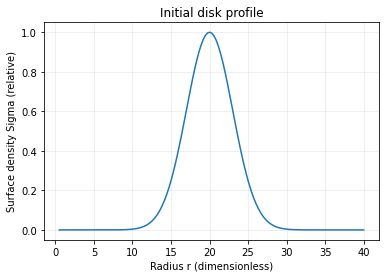

In [14]:
def initial_profile(r, r_peak=20.0, width=3.0):
    """Return a dimensionless ring-shaped surface-density profile."""
    sigma = np.exp(-0.5 * ((r - r_peak) / width) ** 2)
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    return sigma

sigma0 = initial_profile(r)
plt.plot(r, sigma0)
plt.xlabel("Radius r (dimensionless)")
plt.ylabel("Surface density Sigma (relative)")
plt.title("Initial disk profile")
plt.grid(alpha=0.25)

## 3. Mass and time step

The dimensionless disk mass is approximated by $M=2\pi\int r\Sigma\,dr$. Use the trapezoidal rule.

The explicit method requires a small time step for stability. For this grid, we can use the safe estimate $\Delta t=0.35\,\Delta x^2 x_{\min}^2/(3\nu)$, assuming constant viscosity. CFL (Courant-Friedrich-Levy) 


In [18]:
def disk_mass(r, sigma):
# TODO 4: numerically integrate 2*pi*r*sigma with respect to r.
# np.trapz(r*sigma,r)    // or np.trapezoid for newer numpy
    return 2.0 * np.pi * np.trapz(r*sigma,r)

nu = 1.0
safety = 0.35
# TODO 5: calculate the stable time step using the formula above.
dt_stable = safety * dx**2 * x[0]**2 / (3.0 * nu)
print(f"Initial mass: {disk_mass(r, sigma0):.4f}")
print(f"Stable time step: {dt_stable:.2e}")

Initial mass: 944.9766
Stable time step: 5.74e-05


## 4. Evolve the disk in time

The inner grid points of the disk can be approximated using the second derivative as follows:

$$\frac{\partial^2 q}{\partial x^2}\approx\frac{q_{i+1}-2q_i+q_{i-1}}{\Delta x^2},\qquad q=\nu\Sigma x.$$

Then update the surface density using the right-hand side of the equation. Copy the nearest interior value to the first and last elements of the array at every step. The function below provides the loop and saves the results; fill in the `TODO` sections.

**Tip:** in the evolution equation, `x[1:-1]` and `sigma[1:-1]` refer to the interior grid points.

In [32]:
def evolve(sigma_initial, x, nu=1.0, t_end=0.15, n_snapshots=6):
    dx = x[1] - x[0]
    r = x**2
    sigma = sigma_initial.astype(float).copy()
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    nu_profile = np.asarray(nu, dtype=float)
    if nu_profile.ndim == 0:
        nu_profile = np.full_like(x, float(nu_profile))
    if nu_profile.shape != x.shape or not np.all(np.isfinite(nu_profile)) or np.any(nu_profile <= 0):
        raise ValueError("nu must be positive and finite, either as a scalar or one value per grid point")
    dt_stable = 0.35 * dx**2 * x[0]**2 / (3.0 * np.max(nu_profile))
    save_every = max(1, int(np.ceil(t_end / (dt_stable * (n_snapshots - 1)))))
    times = [0.0]
    profiles = [sigma.copy()]
    masses = [disk_mass(r, sigma)]
    t = 0.0
    step = 0

    while t < t_end:
        dt = min(dt_stable, t_end - t)
        q = nu_profile * sigma * x
# TODO 6: calculate the second derivative of q at the interior grid points.
        d2q_dx2 = (q[2:] - 2.0*q[1:-1] + q[:-2])/dx**2

        sigma_next = sigma.copy()
# TODO 7: apply the explicit Euler update using the evolution equation.
        sigma_next[1:-1] += dt*3.0*d2q_dx2 / (4.0*x[1:-1]**3)
        sigma_next[0] = sigma_next[1]
        sigma_next[-1] = sigma_next[-2]
        sigma = sigma_next
        t += dt
        step += 1

        if step % save_every == 0 or t >= t_end:
            times.append(t)
            profiles.append(sigma.copy())
            masses.append(disk_mass(r, sigma))

    return np.array(times), np.array(profiles), np.array(masses)

times, profiles, masses = evolve(sigma0, x, nu=nu)
assert np.all(np.isfinite(profiles))
assert profiles.min() > -1e-10, "Negative density: check the equation and time step."
print(f"Final time reached: {times[-1]:.3f}")

Final time reached: 0.150


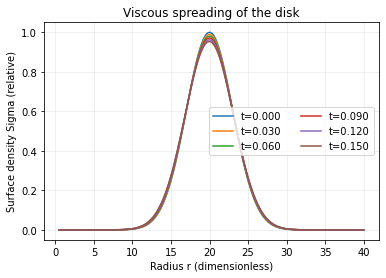

In [33]:
for t, sigma in zip(times, profiles):
    plt.plot(r, sigma, label=f"t={t:.3f}")
plt.xlabel("Radius r (dimensionless)")
plt.ylabel("Surface density Sigma (relative)")
plt.title("Viscous spreading of the disk")
plt.legend(ncol=2)
plt.grid(alpha=0.25)

Mass: 944.9766 -> 944.9766


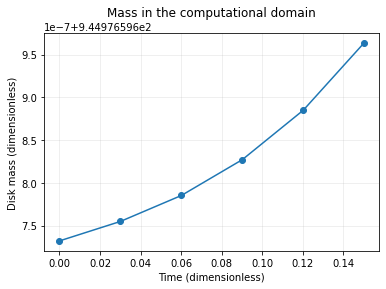

In [34]:
plt.plot(times, masses, marker="o")
plt.xlabel("Time (dimensionless)")
plt.ylabel("Disk mass (dimensionless)")
plt.title("Mass in the computational domain")
plt.grid(alpha=0.25)
print(f"Mass: {masses[0]:.4f} -> {masses[-1]:.4f}")

## 5. Interpret and experiment

Change the value of `nu`, then rerun the time evolution and plots.

1. Which part of the disk spreads outwards, and which part moves inwards?
2. Why can the calculated mass change in a finite computational domain?
3. What happens to the stable time step if you increase the number of grid points?
4. What additional terms would the model need if you wanted to track dust as well?

**Optional:** rerun the calculation with twice the grid resolution and compare the profile. The explicit method requires more time steps on a finer grid.

## Extension: a power-law disk and a dead zone

Replace the Gaussian ring with a power-law profile, $\\Sigma(r)=\\Sigma_0*r^{-p}$. Then define a radial viscosity profile with a low-viscosity annulus: this is a simple representation of a **dead zone**. The transition should be smooth so the viscosity does not jump abruptly from one grid cell to the next.

The evolution function above accepts either one scalar viscosity or an array with one value per grid point. Complete the two functions below, evolve to dimensionless time 0.30, and compare the saved surface-density snapshots and viscosity profile. This prescription is an educational simplification, not a detailed ionization or turbulence model.

In [38]:
def power_law_profile(r, sigma0=1.0, r0=1.0, p=1.0):
    # TODO 8: implement Sigma = sigma0 * (r/r0)**(-p).
    sigma = sigma0*r**(-p)
    # Impose zero gradient by copying the nearest interior value at each edge.
    sigma[0] = sigma[1]
    sigma[-1] = sigma[-2]
    return sigma

def dead_zone_viscosity(r, nu_active=1.0, r_inner=5.0, r_outer=15.0,
                        reduction=0.01, edge_width=1.0):
    """Return a smooth viscosity profile with a low-viscosity annular dead zone."""
    inner_edge = 0.5 * (1.0 + np.tanh((r - r_inner) / edge_width))
    outer_edge = 0.5 * (1.0 + np.tanh((r_outer - r) / edge_width))
    dead_zone = inner_edge * outer_edge
    return nu_active * (1.0 - (1.0 - reduction) * dead_zone)

sigma_power = power_law_profile(r, sigma0=1.0, r0=1.0, p=1.0)
nu_dead = dead_zone_viscosity(r)

# TODO 11: evolve using nu_dead, t_end=0.30, and n_snapshots=6.
times_dz, profiles_dz, masses_dz = 


assert np.all(np.isfinite(profiles_dz))
assert profiles_dz.min() > -1e-10

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for t, sigma_t in zip(times_dz, profiles_dz):
    axes[0].plot(r, sigma_t, label=f"t={t:.2f}")
axes[0].set_xlabel("Radius r (dimensionless)")
axes[0].set_ylabel("Surface density Sigma (relative)")
axes[0].set_title("Power-law disk with a dead zone")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(r, nu_dead)
axes[1].set_xlabel("Radius r (dimensionless)")
axes[1].set_ylabel("Viscosity nu (relative)")
axes[1].set_title("Prescribed viscosity profile")
axes[1].grid(alpha=0.25)
plt.tight_layout()

TypeError: cannot unpack non-iterable ellipsis object